# Band-envelope EDA: what do the clusters look like?

Mouse 720762, deep prelimbic LFP (PL5, probe F). For 5, 6, 8, 10 and 20 overlapping bands (log-spaced from 1 to
80 Hz, each overlapping half of its neighbours), with stimulus periods included or excluded, and for the awake,
isoflurane and full windows:

1. The distribution of the data along each band axis.
2. Centered and uncentered PCA, with the top 2 and top 3 components.
3. The data projected onto each motif direction (found with the relaxed version, or the original if the relaxed one finds none).

**Hypotheses tested**

- Along a motif direction, are there only two poles, or sub-poles that should count as separate motifs?
- Should baseline activity count as a motif of its own?

**Choices that matter**

- **Stimulus excluded** removes the electrical and the visual stimulus blocks (plus 5 s either side). Stimulus included keeps the whole recording.
- **Centered PCA** runs on the z-scored envelopes. Uncentered PCA runs on envelopes divided by their SD but not mean-subtracted, so its first component captures the average spectrum. On z-scored data the two would be identical.
- **Chunk length** for the motif search is lengthened when needed, so the significance test's band shifts (20 s × band index) fit inside each chunk.
- **Sub-poles are tested in two ways:** bimodality along the motif axis, and, within each pole, bimodality in the direction perpendicular to the axis that varies most. Two different patterns can share one pole; the second test catches that.
- **Nulls:** the dip tests use the shuffled-band null (each band shifted in time within its stretch). The baseline test uses a Gaussian with the same band correlations as the data, because correlated bands alone make quiet seconds more common.

Many tests are run below, so some p < 0.05 results are expected by chance (see the summary).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import band_eda as be
from src import session_data as sd
%matplotlib inline

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
CACHE = REPO / "data" / "processed" / "band_eda"
OUT = REPO / "data" / "out" / "2026-11-08_band_eda"
OUT.mkdir(parents=True, exist_ok=True)
N_NULL = 50
STATE_COLORS = {"awake": "#1f77b4", "induction": "#ff7f0e", "isoflurane": "#d62728"}

info, channel = be.build_cache(NWB, CACHE)
data = {(n, s, w): be.window_data(be.load(CACHE, n, s), info, w)
        for n in be.BAND_COUNTS for s in be.STIM for w in be.WINDOWS}

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=120, bbox_inches="tight")

print(f"PL5 channel {channel}")
pd.DataFrame([{"bands": n, "stimulus": s, "window": w, "seconds": d.z.shape[0], "stretches": len(np.unique(d.piece))}
              for (n, s, w), d in data.items() if n == 10]).set_index(["stimulus", "window"])

PL5 channel 254


bands  seconds  stretches
stimulus window                               
included awake          10     3238          1
         isoflurane     10     3672          1
         full           10     7088          1
excluded awake          10      958          3
         isoflurane     10     1399          3
         full           10     2535          5

In [2]:
pd.DataFrame({n: be.band_names(be.band_set(n)) + [""] * (20 - n) for n in be.BAND_COUNTS}).T.iloc[:, :20]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
5,1.0-4.3,2.1-8.9,4.3-18.6,8.9-38.5,18.6-80.0,,,,,,,,,,,,,,,
6,1.0-3.5,1.9-6.5,3.5-12.2,6.5-22.9,12.2-42.8,22.9-80.0,,,,,,,,,,,,,,
8,1.0-2.6,1.6-4.3,2.6-7.0,4.3-11.4,7.0-18.6,11.4-30.2,18.6-49.2,30.2-80.0,,,,,,,,,,,,
10,1.0-2.2,1.5-3.3,2.2-4.9,3.3-7.3,4.9-10.9,7.3-16.3,10.9-24.2,16.3-36.1,24.2-53.7,36.1-80.0,,,,,,,,,,
20,1.0-1.5,1.2-1.9,1.5-2.3,1.9-2.8,2.3-3.5,2.8-4.3,3.5-5.3,4.3-6.5,5.3-8.1,6.5-9.9,8.1-12.2,9.9-15.1,12.2-18.6,15.1-22.9,18.6-28.2,22.9-34.7,28.2-42.8,34.7-52.7,42.8-64.9,52.7-80.0


## 1. Distribution along each band axis

Z-scored envelope of each band. Filled: stimulus included. Outline: stimulus excluded. A cluster would show as a separate hump.

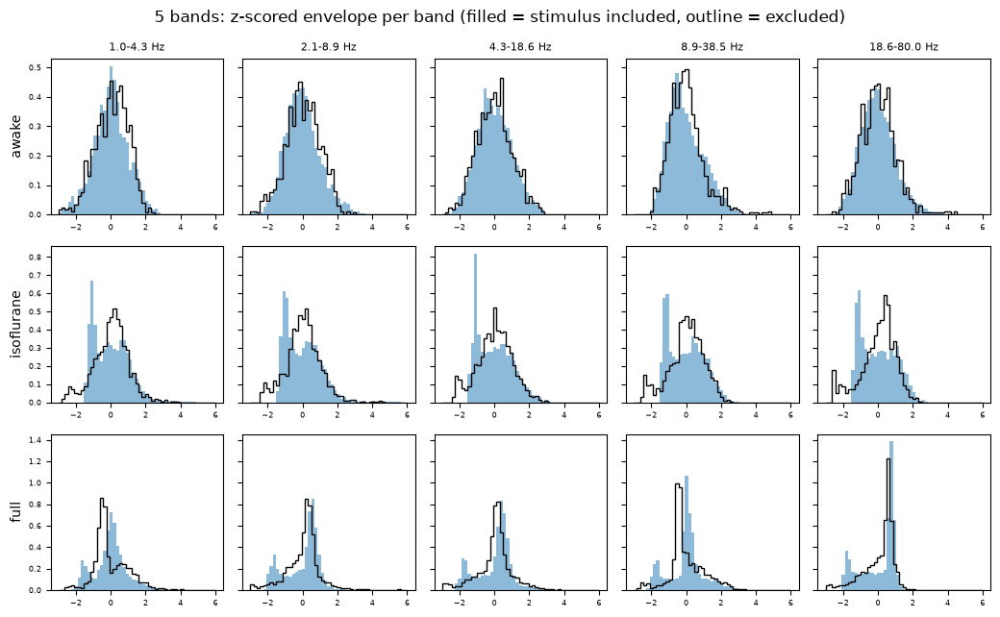

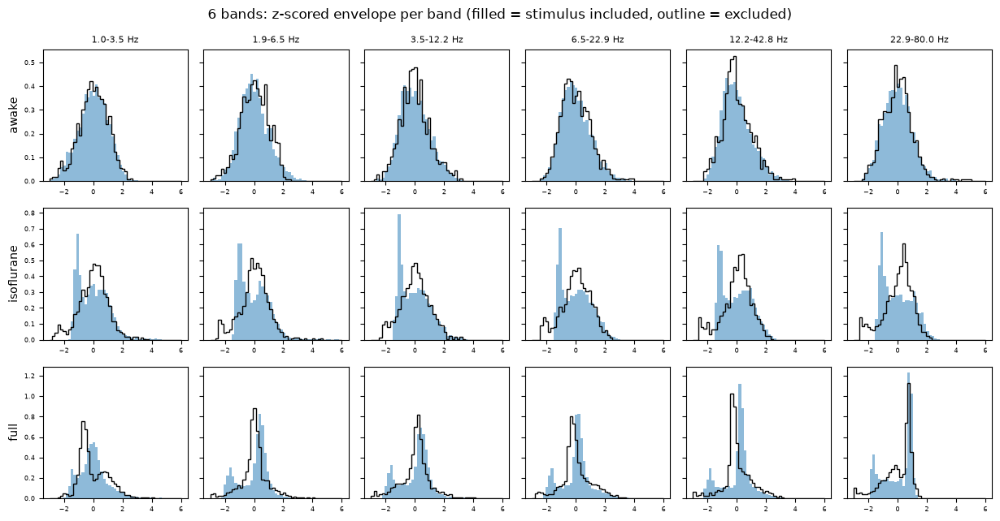

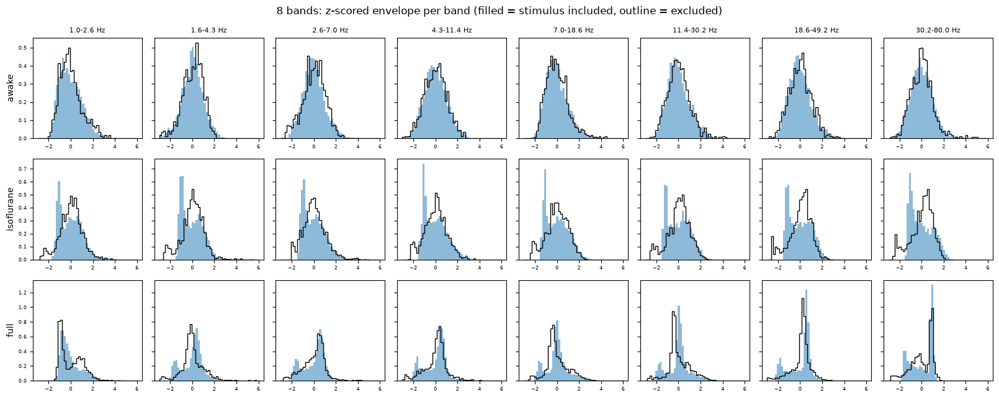

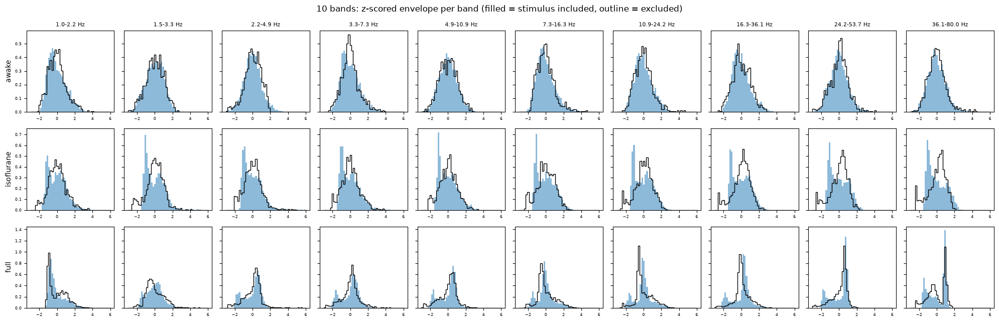

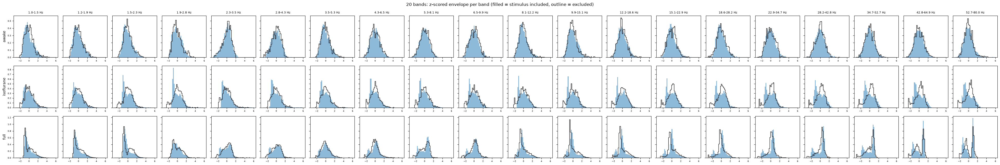

In [3]:
for n in be.BAND_COUNTS:
    names = be.band_names(be.band_set(n))
    fig, axes = plt.subplots(3, n, figsize=(1.9 * n + 1, 6.5), sharey="row", squeeze=False)
    for r, w in enumerate(be.WINDOWS):
        for c in range(n):
            ax = axes[r, c]
            bins = np.linspace(-3, 6, 50)
            ax.hist(data[(n, "included", w)].z[:, c], bins=bins, density=True, color="C0", alpha=0.5)
            ax.hist(data[(n, "excluded", w)].z[:, c], bins=bins, density=True, histtype="step", color="k", lw=1)
            if r == 0:
                ax.set_title(f"{names[c]} Hz", fontsize=8)
            if c == 0:
                ax.set_ylabel(w)
            ax.tick_params(labelsize=6)
    fig.suptitle(f"{n} bands: z-scored envelope per band (filled = stimulus included, outline = excluded)")
    fig.tight_layout()
    save(fig, f"1_band_distributions_{n}")
    plt.show()

## 2. PCA: top 2 and top 3 components

For each band count, one figure. Rows: window × stimulus option. Left four panels: centered PCA (PC1–2, PC1–3, PC2–3, then all three). Right four: uncentered. Colours: awake blue, induction orange, isoflurane red.

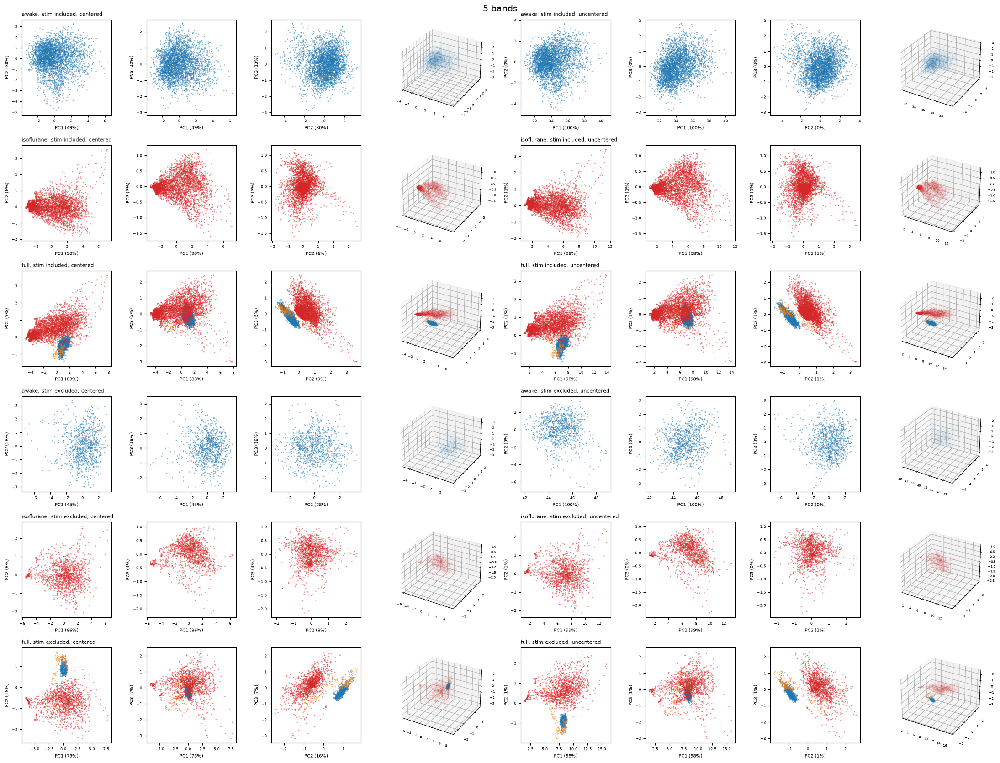

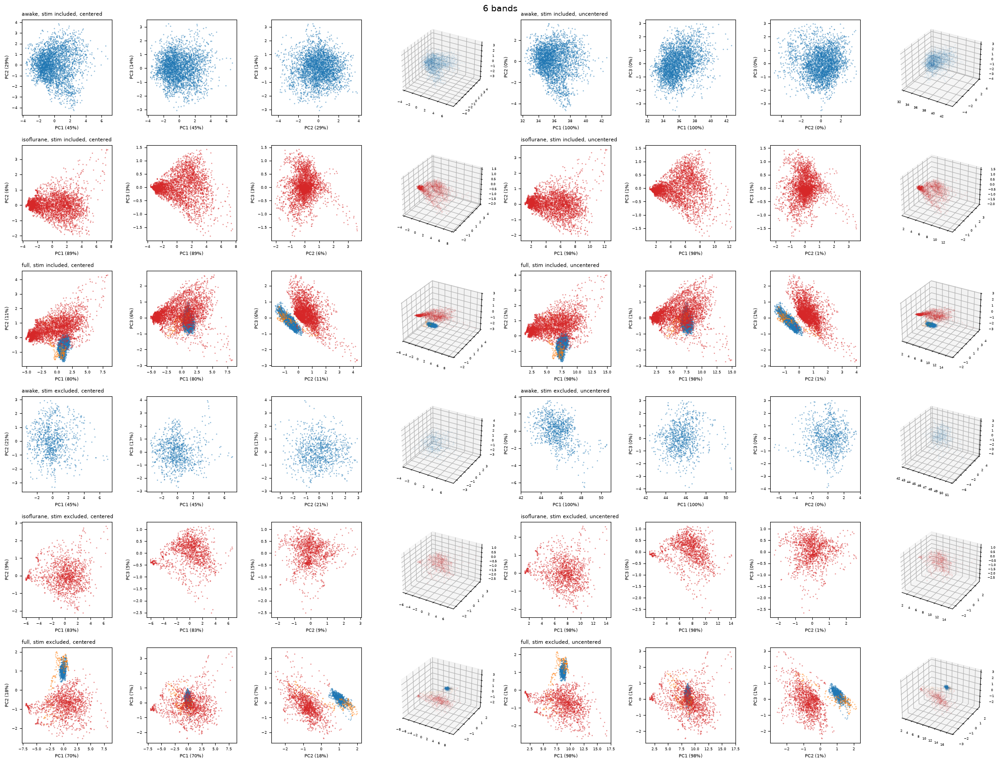

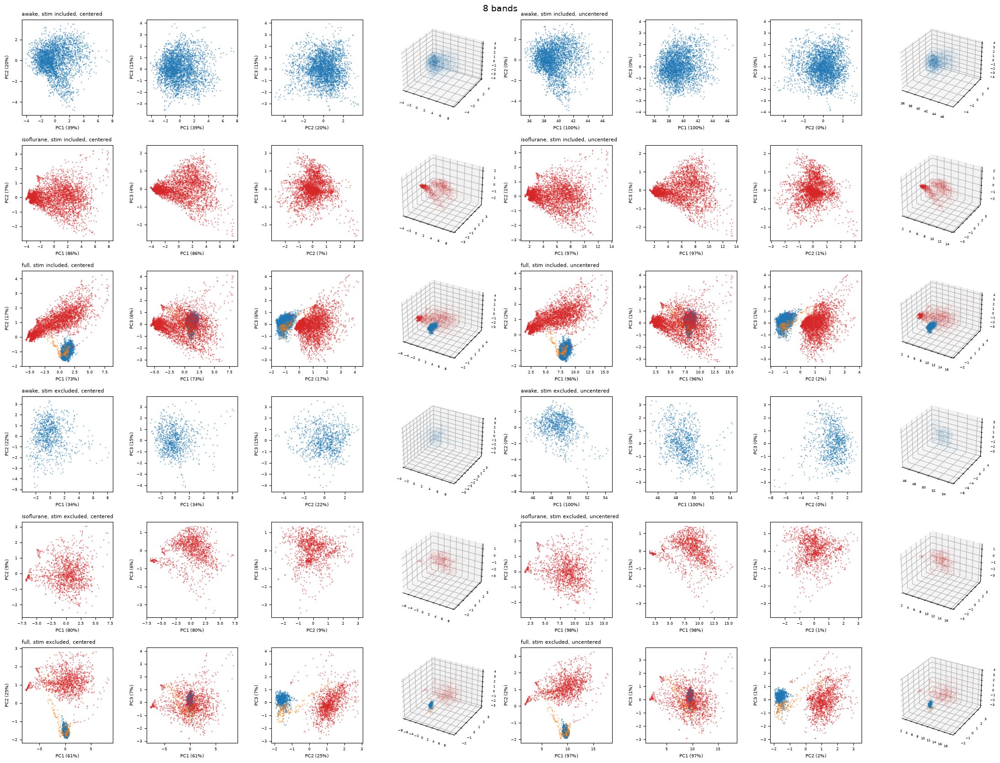

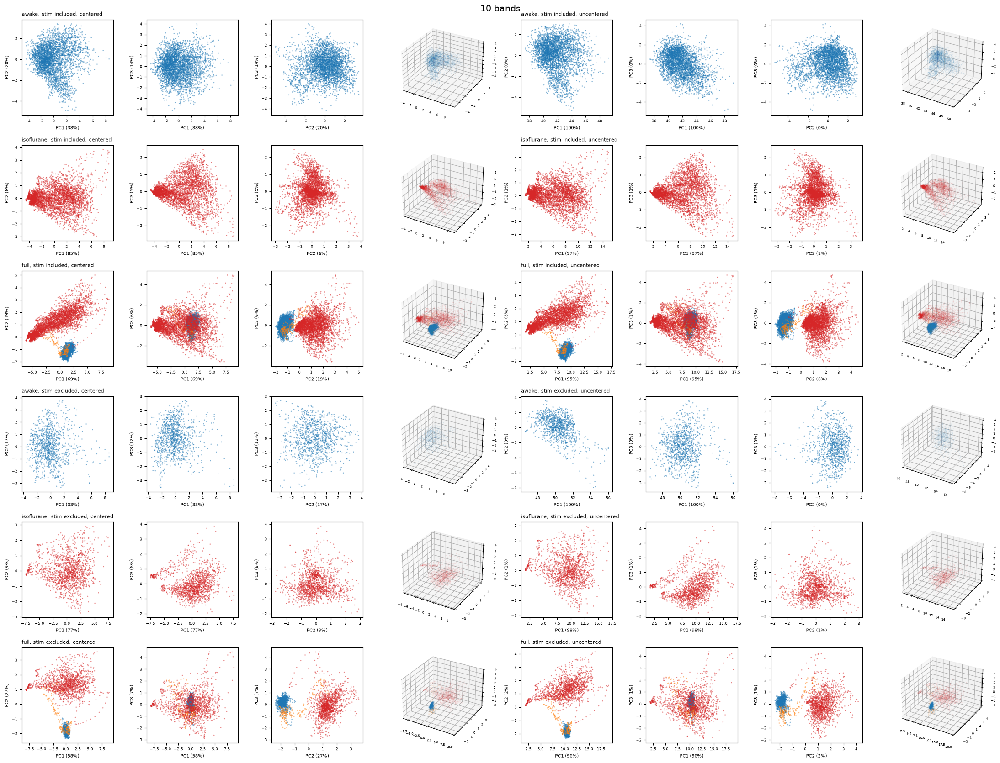

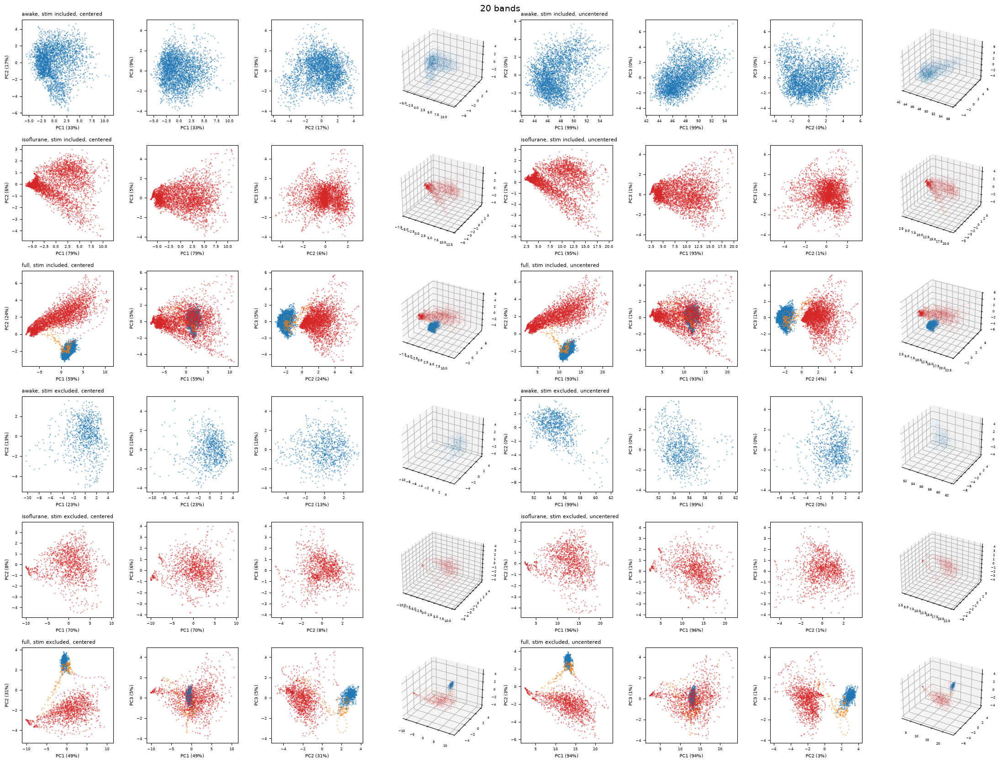

PC1                 PC2                 PC3  \
PCA                       centered uncentered centered uncentered centered   
bands stimulus window                                                        
5     excluded awake          0.45       1.00     0.28       0.00     0.18   
               full           0.73       0.98     0.16       0.01     0.07   
               isoflurane     0.86       0.99     0.08       0.01     0.04   
      included awake          0.49       1.00     0.30       0.00     0.13   
               full           0.83       0.98     0.09       0.01     0.05   
               isoflurane     0.90       0.98     0.06       0.01     0.03   
6     excluded awake          0.45       1.00     0.21       0.00     0.17   
               full           0.70       0.98     0.18       0.01     0.07   
               isoflurane     0.83       0.98     0.09       0.01     0.05   
      included awake          0.45       1.00     0.29       0.00     0.14   
               full           0.80       0.98     0.11       0.01     0.06   
               isoflurane     0.89       0.98     0.06       0.01     0.03   
8     excluded awake          0.34       1.00     0.22       0.00     0.15   
               full           0.61       0.97     0.25       0.02     0.07   
               isoflurane     0.80       0.98     0.09       0.01     0.06   
      included awake          0.39       1.00     0.20       0.00     0.15   
               full           0.73       0.96     0.17       0.02     0.06   
               isoflurane     0.86       0.97     0.07       0.01     0.04   
10    excluded awake          0.33       1.00     0.17       0.00     0.12   
               full           0.58       0.96     0.27       0.02     0.07   
               isoflurane     0.77       0.98     0.09       0.01     0.06   
      included awake          0.38       1.00     0.20       0.00     0.14   
               full           0.69       0.95     0.19       0.03     0.06   
               isoflurane     0.85       0.97     0.06       0.01     0.05   
20    excluded awake          0.23       0.99     0.13       0.00     0.10   
               full           0.49       0.94     0.31       0.03     0.05   
               isoflurane     0.70       0.96     0.08       0.01     0.06   
      included awake          0.33       0.99     0.17       0.00     0.09   
               full           0.59       0.93     0.24       0.04     0.05   
               isoflurane     0.79       0.95     0.06       0.01     0.05   

                                      
PCA                       uncentered  
bands stimulus window                 
5     excluded awake            0.00  
               full             0.01  
               isoflurane       0.00  
      included awake            0.00  
               full             0.01  
               isoflurane       0.01  
6     excluded awake            0.00  
               full             0.01  
               isoflurane       0.00  
      included awake            0.00  
               full             0.01  
               isoflurane       0.01  
8     excluded awake            0.00  
               full             0.01  
               isoflurane       0.01  
      included awake            0.00  
               full             0.01  
               isoflurane       0.01  
10    excluded awake            0.00  
               full             0.01  
               isoflurane       0.01  
      included awake            0.00  
               full             0.01  
               isoflurane       0.01  
20    excluded awake            0.00  
               full             0.01  
               isoflurane       0.01  
      included awake            0.00  
               full             0.01  
               isoflurane       0.01

In [4]:
pca_rows = []
pcs = {}
for n in be.BAND_COUNTS:
    fig = plt.figure(figsize=(22, 17))
    for r, (s, w) in enumerate([(s, w) for s in be.STIM for w in be.WINDOWS]):
        d = data[(n, s, w)]
        colors = [STATE_COLORS[x] for x in d.state]
        for half, (center, X) in enumerate([(True, d.z), (False, d.scaled)]):
            vt, sc, var = be.pca(X, center=center)
            pcs[(n, s, w, center)] = (vt, var)
            pca_rows.append({"bands": n, "stimulus": s, "window": w, "PCA": "centered" if center else "uncentered",
                             **{f"PC{i + 1}": var[i] for i in range(3)}})
            for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)]):
                ax = fig.add_subplot(6, 8, r * 8 + half * 4 + k + 1)
                ax.scatter(sc[:, i], sc[:, j], s=1, c=colors, alpha=0.4, rasterized=True)
                ax.set_xlabel(f"PC{i + 1} ({var[i]:.0%})", fontsize=7); ax.set_ylabel(f"PC{j + 1} ({var[j]:.0%})", fontsize=7)
                ax.tick_params(labelsize=6)
                if k == 0:
                    ax.set_title(f"{w}, stim {s}, {'centered' if center else 'uncentered'}", fontsize=8, loc="left")
            ax = fig.add_subplot(6, 8, r * 8 + half * 4 + 4, projection="3d")
            ax.scatter(sc[:, 0], sc[:, 1], sc[:, 2], s=0.5, c=colors, alpha=0.3, rasterized=True)
            ax.tick_params(labelsize=5)
    fig.suptitle(f"{n} bands", fontsize=14)
    fig.tight_layout()
    save(fig, f"2_pca_{n}")
    plt.show()

pd.DataFrame(pca_rows).pivot_table(index=["bands", "stimulus", "window"], columns="PCA", values=["PC1", "PC2", "PC3"]).round(2)

What the components look like (band loadings), for the 10-band set. Uncentered PC1 is compared with the average spectrum of the window (the baseline).

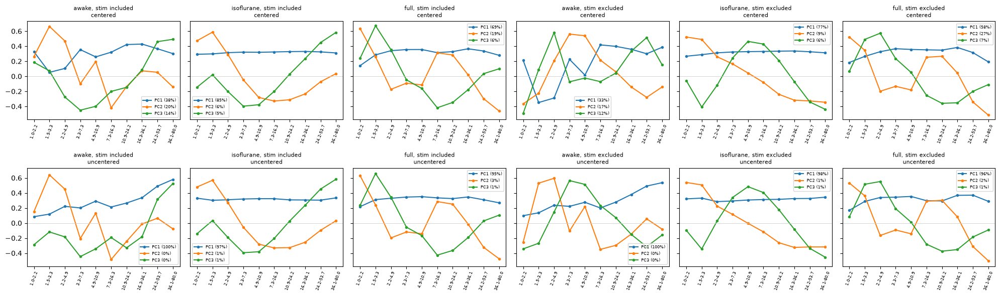

stimulus excluded                   included                  
window      awake   full isoflurane    awake   full isoflurane
bands                                                         
5           0.998  0.980      0.986    0.998  0.979      0.980
6           0.998  0.977      0.983    0.997  0.975      0.977
8           0.997  0.967      0.979    0.997  0.962      0.971
10          0.997  0.962      0.975    0.996  0.955      0.966
20          0.994  0.943      0.965    0.993  0.933      0.952

In [5]:
n = 10
names = be.band_names(be.band_set(n))
fig, axes = plt.subplots(2, 6, figsize=(20, 6), sharey=True)
for col, (s, w) in enumerate([(s, w) for s in be.STIM for w in be.WINDOWS]):
    for row, center in enumerate((True, False)):
        vt, var = pcs[(n, s, w, center)]
        ax = axes[row, col]
        for i in range(3):
            ax.plot(vt[i], "-o", ms=3, label=f"PC{i + 1} ({var[i]:.0%})")
        ax.axhline(0, color="0.8", lw=0.6)
        ax.set_xticks(range(n), names, rotation=70, fontsize=6)
        ax.set_title(f"{w}, stim {s}\n{'centered' if center else 'uncentered'}", fontsize=8)
        ax.legend(fontsize=6)
fig.tight_layout(); save(fig, "2_pca_loadings_10"); plt.show()

rows = []
for (n_, s, w, center), (vt, var) in pcs.items():
    if not center:
        mean = data[(n_, s, w)].scaled.mean(axis=0)
        rows.append({"bands": n_, "stimulus": s, "window": w, "uncentered PC1 share": var[0],
                     "|r| uncentered PC1 vs average spectrum": abs(np.corrcoef(vt[0], mean)[0, 1])})
pd.DataFrame(rows).pivot_table(index="bands", columns=["stimulus", "window"], values="uncentered PC1 share").round(3)

## 3. Motif directions

Motifs from the relaxed version (5-minute chunks, longer when needed), or from the original rules if the relaxed version finds none.

In [6]:
motifs = {}
rows = []
for key, d in data.items():
    n = key[0]
    axes_, version, length = be.motif_axes(d, n)
    motifs[key] = (axes_, version)
    rows.append({"bands": n, "stimulus": key[1], "window": key[2], "motifs": axes_.shape[1], "from": version, "chunk (s)": length})
pd.DataFrame(rows).pivot_table(index="bands", columns=["stimulus", "window"], values="motifs", aggfunc="first")

stimulus excluded                 included                
window      awake full isoflurane    awake full isoflurane
bands                                                     
5               1    1          2        2    0          1
6               1    1          2        1    1          1
8               2    1          2        2    1          2
10              2    1          3        1    1          3
20              1    1          3        1    1          0

In [7]:
pd.DataFrame(rows).pivot_table(index="bands", columns=["stimulus", "window"], values="from", aggfunc="first")

stimulus  excluded                     included                     
window       awake     full isoflurane    awake      full isoflurane
bands                                                               
5          relaxed  relaxed    relaxed  relaxed  original    relaxed
6          relaxed  relaxed    relaxed  relaxed   relaxed    relaxed
8          relaxed  relaxed    relaxed  relaxed   relaxed    relaxed
10         relaxed  relaxed    relaxed  relaxed   relaxed    relaxed
20        original  relaxed    relaxed  relaxed   relaxed   original

Running every test on every motif (takes a while).

In [8]:
tests = []
scores = {}
for key, (axes_, version) in motifs.items():
    d = data[key]
    for m in range(axes_.shape[1]):
        r = be.axis_tests(d, axes_[:, m], n_null=N_NULL, seed=m)
        scores[key + (m,)] = (r.pop("score"), r.pop("null_scores"))
        tests.append({"bands": key[0], "stimulus": key[1], "window": key[2], "motif": m + 1, "from": version, **r})
tests = pd.DataFrame(tests)
tests.to_csv(OUT / "axis_tests.csv", index=False)
tests[["bands", "stimulus", "window", "motif", "p_dip_axis", "p_dip_plus", "p_dip_minus"]].round(3)

,bands,stimulus,window,motif,p_dip_axis,p_dip_plus,p_dip_minus
0,5,included,awake,1,0.098,0.569,0.412
1,5,included,awake,2,0.059,0.980,0.373
2,5,included,isoflurane,1,0.588,0.941,0.980
3,5,excluded,awake,1,0.196,0.196,0.294
4,5,excluded,isoflurane,1,0.020,0.294,0.412
5,5,excluded,isoflurane,2,0.392,0.333,0.353
6,5,excluded,full,1,0.020,0.039,0.706
7,6,included,awake,1,0.216,0.725,0.902
8,6,included,isoflurane,1,0.039,0.686,0.941
9,6,included,full,1,0.020,0.941,0.510


## 4. Data along each motif axis

One figure per band count. Rows: window × stimulus option. One panel per motif: histogram of seconds along the axis (+ pole right, opponent left), coloured by state, with the shuffled-band null as a black line. p = dip test against the null (one peak vs more).

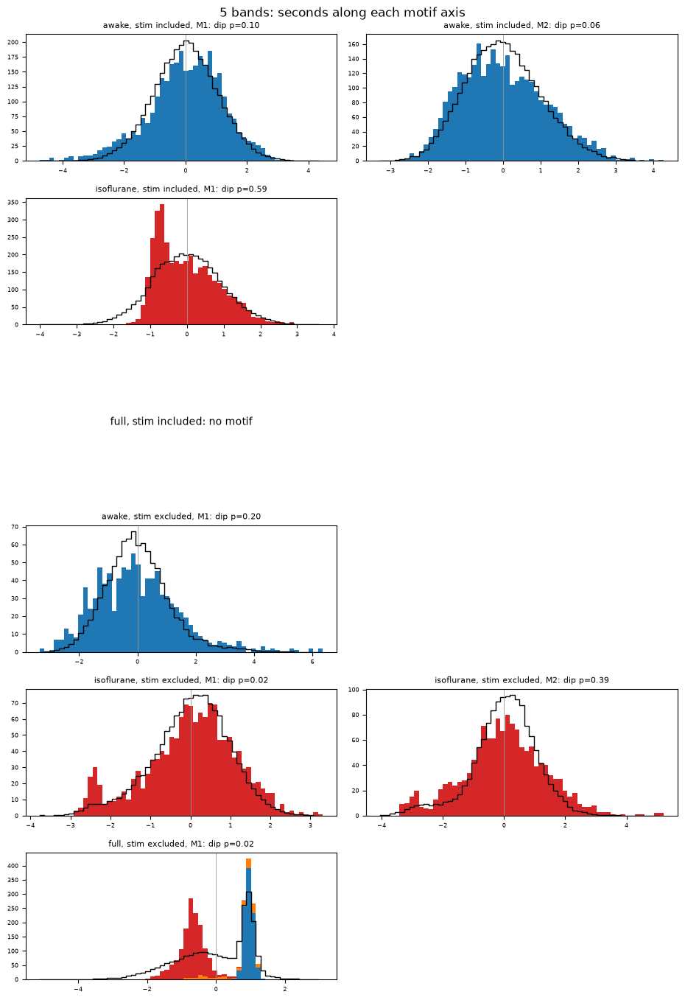

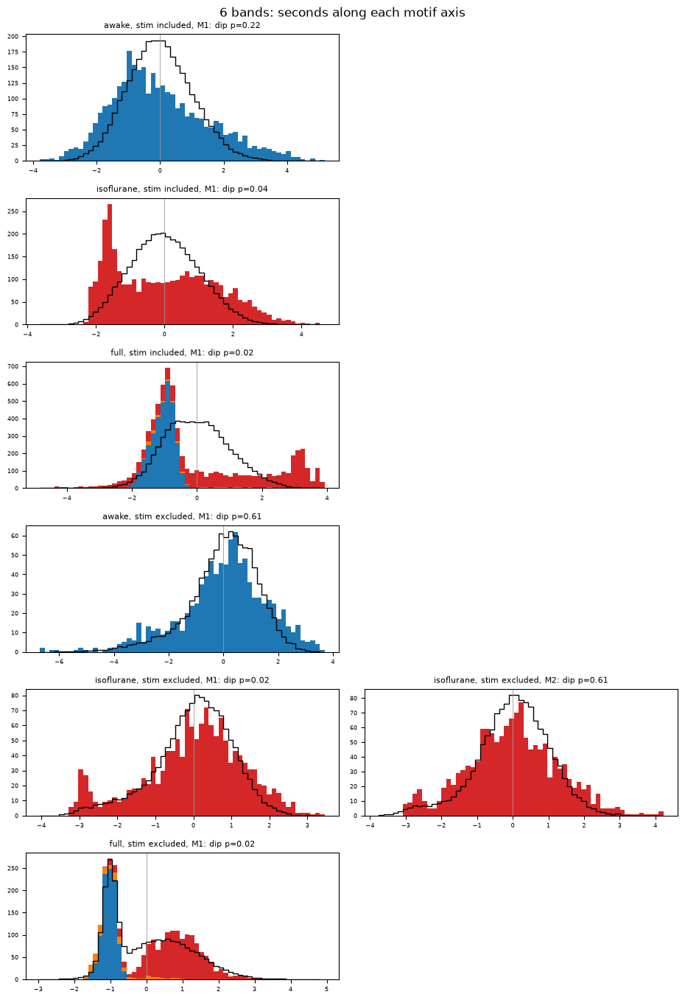

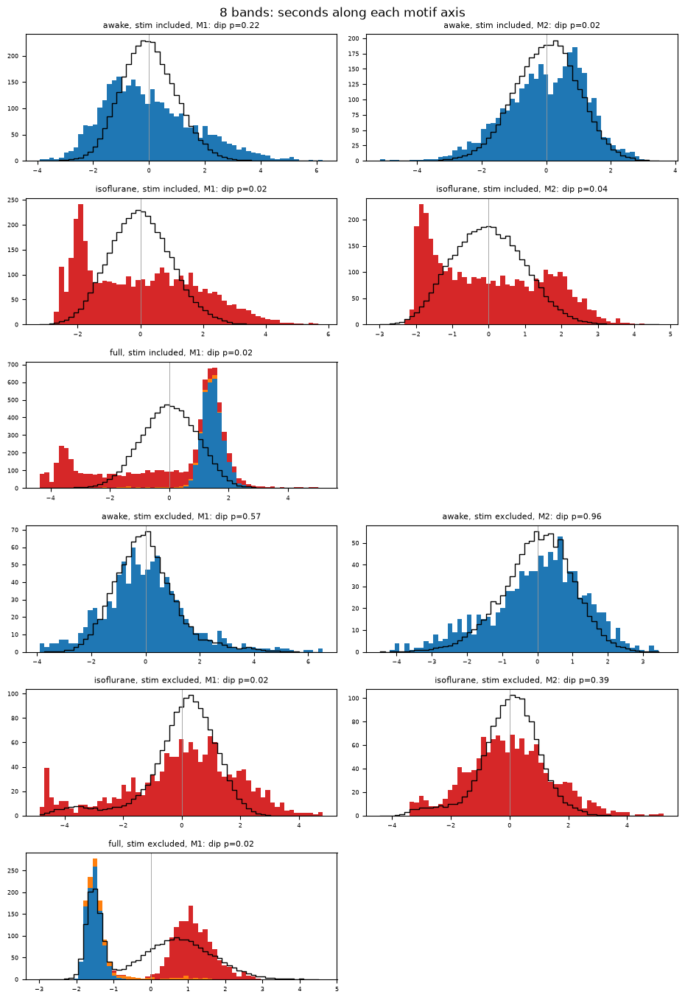

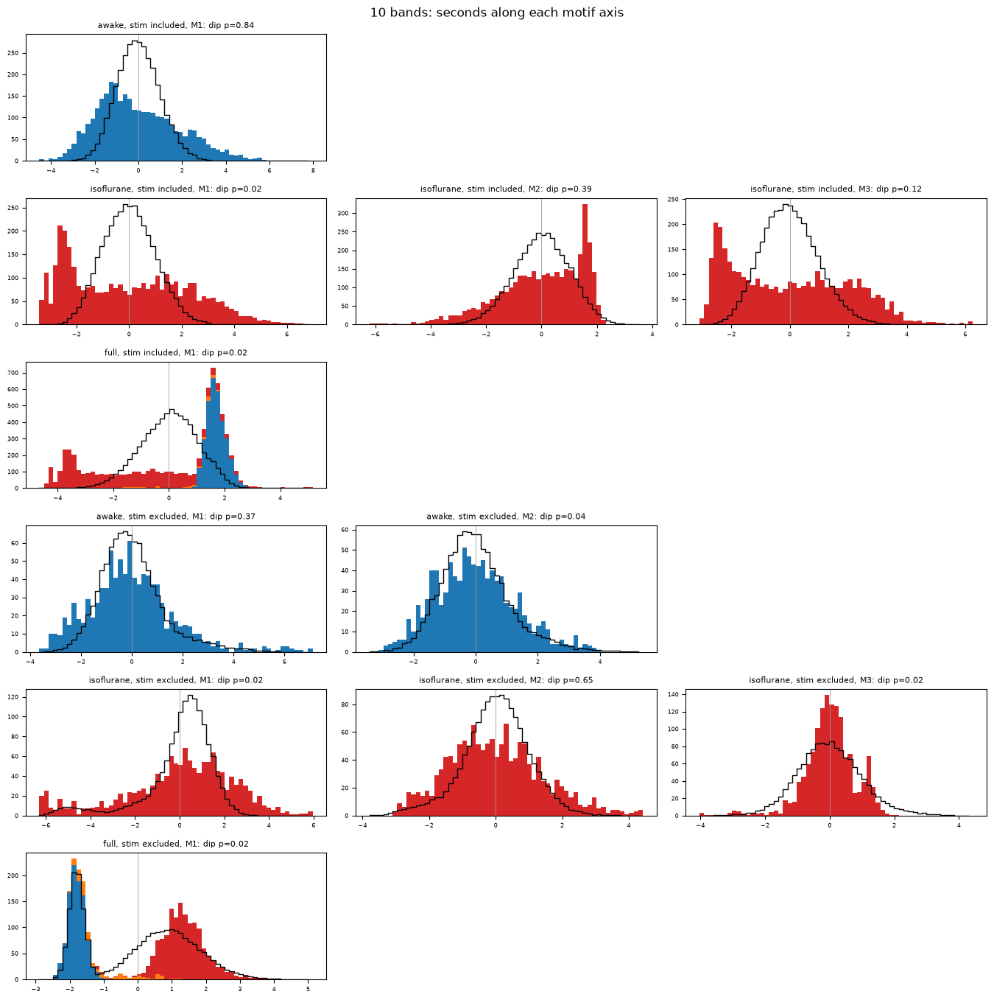

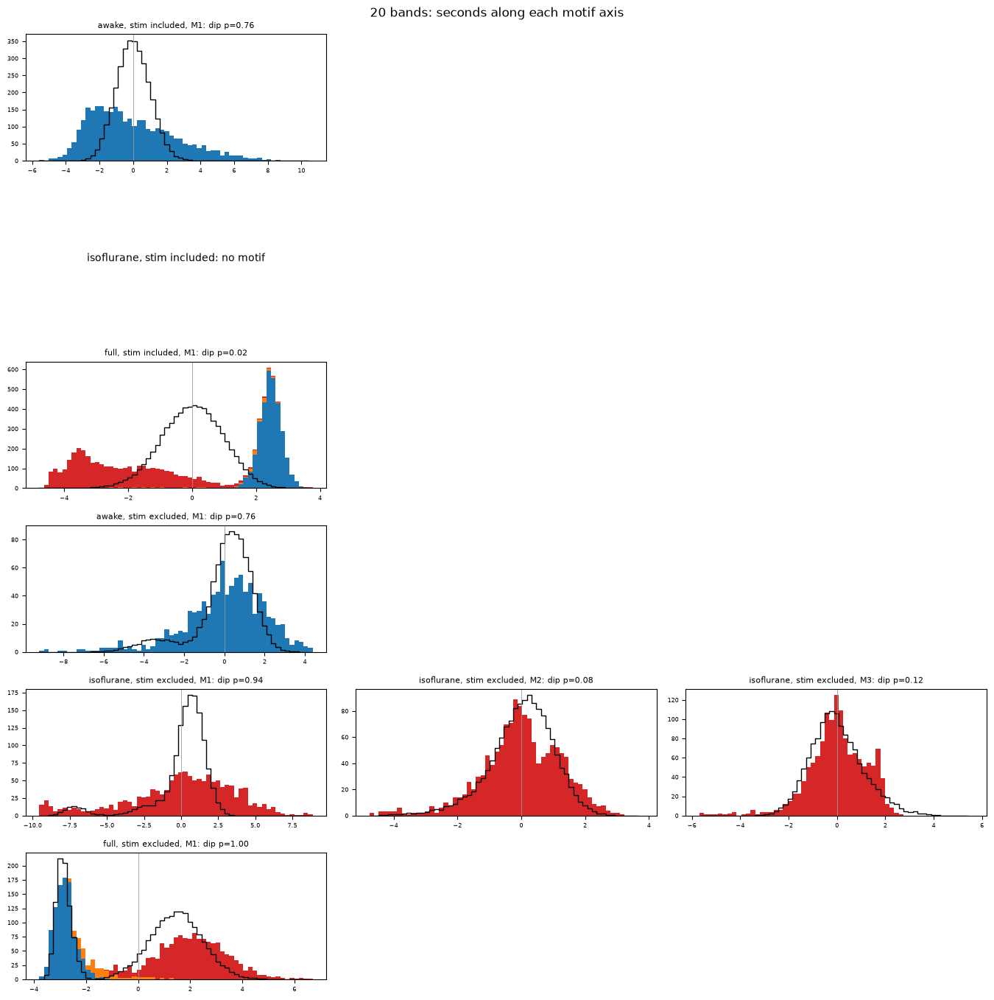

In [9]:
for n in be.BAND_COUNTS:
    conds = [(s, w) for s in be.STIM for w in be.WINDOWS]
    max_m = max(motifs[(n, s, w)][0].shape[1] for s, w in conds) or 1
    fig, axes = plt.subplots(len(conds), max_m, figsize=(4.2 * max_m + 1, 2.3 * len(conds)), squeeze=False)
    for r, (s, w) in enumerate(conds):
        d = data[(n, s, w)]
        k = motifs[(n, s, w)][0].shape[1]
        for m in range(max_m):
            ax = axes[r, m]
            if m >= k:
                ax.axis("off")
                if m == 0:
                    ax.text(0.5, 0.5, f"{w}, stim {s}: no motif", ha="center", transform=ax.transAxes)
                continue
            score, nulls = scores[(n, s, w, m)]
            edges = np.linspace(min(score.min(), nulls.min()), max(score.max(), nulls.max()), 60)
            parts = [(score[d.state == g], STATE_COLORS[g]) for g in ("awake", "induction", "isoflurane") if (d.state == g).any()]
            ax.hist([p[0] for p in parts], bins=edges, stacked=True, color=[p[1] for p in parts])
            ax.step(edges[:-1], np.array([np.histogram(x, edges)[0] for x in nulls]).mean(axis=0), where="post", color="k", lw=1)
            ax.axvline(0, color="0.6", lw=0.6)
            row = tests[(tests.bands == n) & (tests.stimulus == s) & (tests.window == w) & (tests.motif == m + 1)].iloc[0]
            ax.set_title(f"{w}, stim {s}, M{m + 1}: dip p={row.p_dip_axis:.2f}", fontsize=8)
            ax.tick_params(labelsize=6)
    fig.suptitle(f"{n} bands: seconds along each motif axis", fontsize=12)
    fig.tight_layout()
    save(fig, f"4_motif_axes_{n}")
    plt.show()

## 5. Sub-poles: is one pole really two motifs?

Within each pole (seconds more than 0.5 SD from zero), the data is projected onto the direction perpendicular to the motif axis that varies most. If that is bimodal beyond the null, the pole contains two different patterns. The table lists every pole that passes p ≤ 0.05; the figures show, for each, the two sub-groups' average band profiles.

In [10]:
poles = tests.melt(id_vars=["bands", "stimulus", "window", "motif", "from"], value_vars=["p_dip_plus", "p_dip_minus"],
                   var_name="pole", value_name="p").dropna()
poles["pole"] = poles.pole.map({"p_dip_plus": "+", "p_dip_minus": "-"})
hits = poles[poles.p <= 0.05].sort_values("p")
print(f"{len(hits)} of {len(poles)} poles split at p <= 0.05 (about {0.05 * len(poles):.0f} expected by chance)")
hits.round(3)

7 of 84 poles split at p <= 0.05 (about 4 expected by chance)


,bands,stimulus,window,motif,from,pole,p
14,8,included,awake,1,relaxed,+,0.020
24,10,included,awake,1,relaxed,+,0.020
55,6,excluded,full,1,relaxed,-,0.020
75,10,excluded,isoflurane,3,relaxed,-,0.020
80,20,excluded,isoflurane,1,relaxed,-,0.020
6,5,excluded,full,1,relaxed,+,0.039
61,8,excluded,awake,1,relaxed,-,0.039


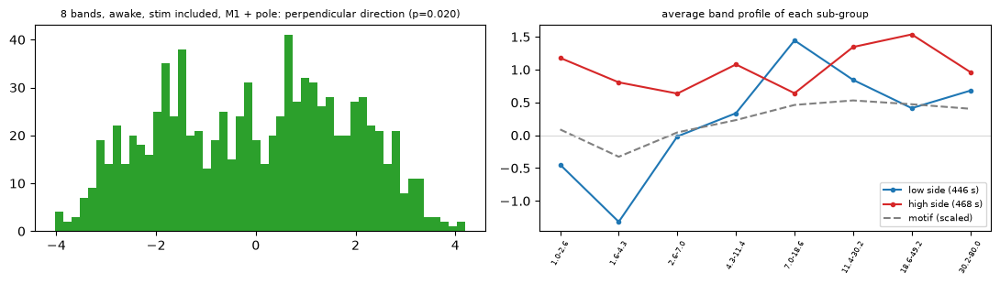

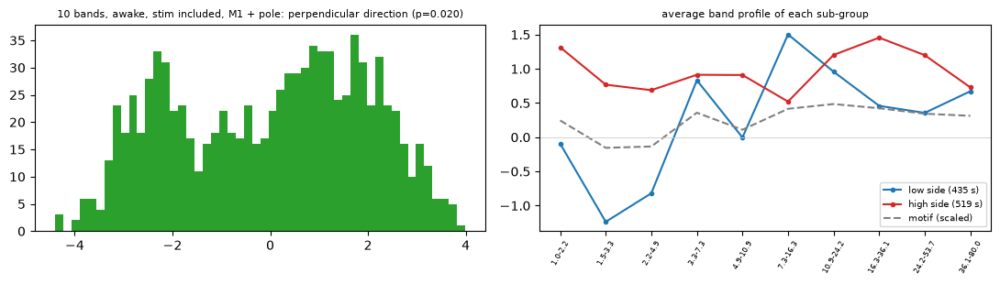

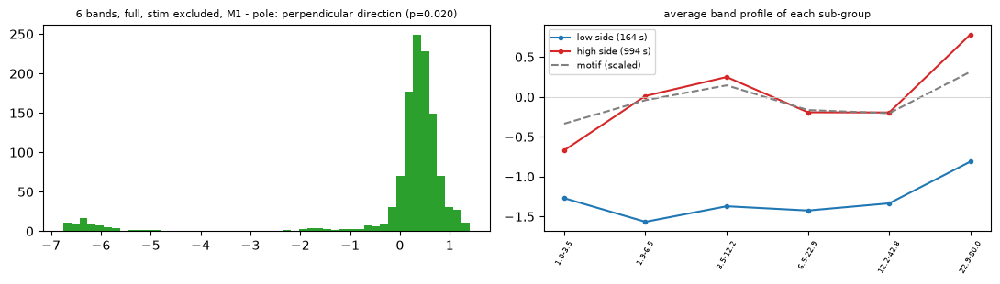

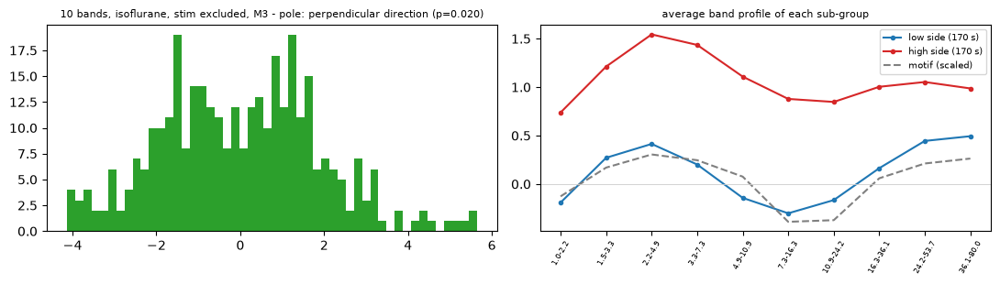

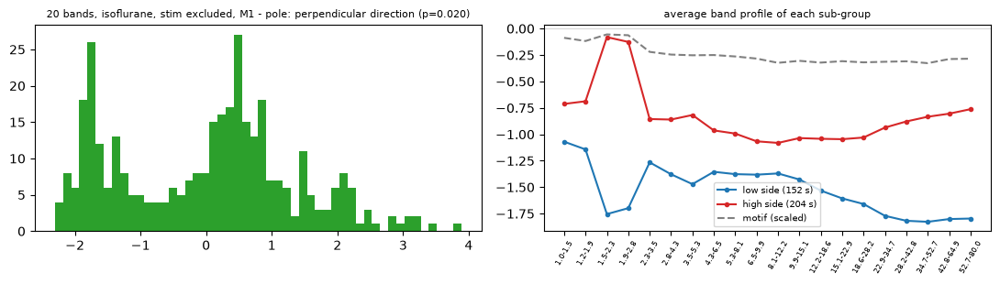

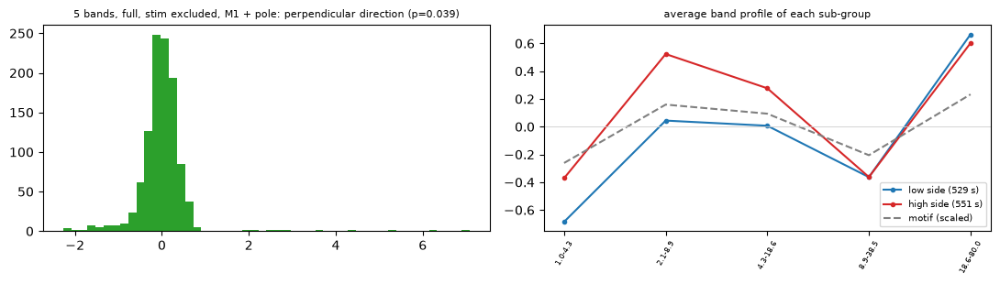

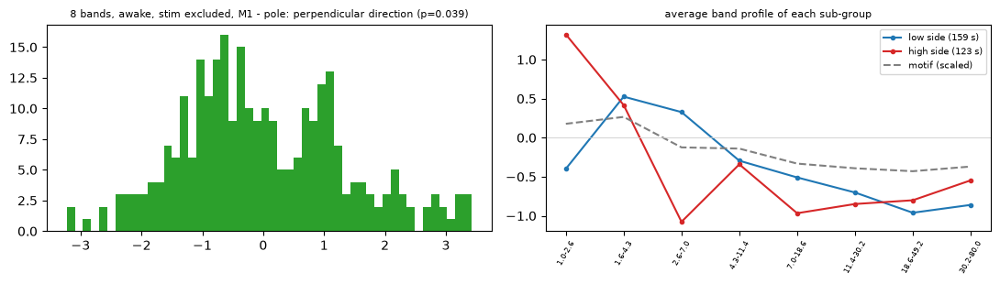

In [11]:
for _, h in hits.head(8).iterrows():
    key = (h.bands, h.stimulus, h.window)
    d = data[key]
    axis = motifs[key][0][:, h.motif - 1]
    axis = axis / np.linalg.norm(axis)
    _, members, (direction, sc) = be.pole_split(d.z, axis, 1 if h.pole == "+" else -1)
    names = be.band_names(be.band_set(h.bands))
    Zp = d.z[members]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].hist(sc, bins=50, color="C2")
    axes[0].set_title(f"{h.bands} bands, {h.window}, stim {h.stimulus}, M{h.motif} {h.pole} pole: perpendicular direction (p={h.p:.3f})", fontsize=8)
    for lab, sel, c in (("low side", sc < 0, "C0"), ("high side", sc >= 0, "C3")):
        axes[1].plot(Zp[sel].mean(axis=0), "-o", ms=3, color=c, label=f"{lab} ({sel.sum()} s)")
    axes[1].plot((1 if h.pole == "+" else -1) * axis * np.abs(Zp).mean(), "--", color="0.5", label="motif (scaled)")
    axes[1].axhline(0, color="0.8", lw=0.6)
    axes[1].set_xticks(range(len(names)), names, rotation=60, fontsize=6)
    axes[1].legend(fontsize=7); axes[1].set_title("average band profile of each sub-group", fontsize=8)
    fig.tight_layout(); plt.show()

The only split that repeats across band sets (awake, stimulus included, M1 + pole, at 8 and 10 bands): where do its two groups fall in time?

In [ ]:
# Where do the two groups in the awake, stimulus-included + pole fall in time?
for n in (8, 10):
    d = data[(n, "included", "awake")]
    axis = motifs[(n, "included", "awake")][0][:, 0]
    _, members, (direction, sc) = be.pole_split(d.z, axis / np.linalg.norm(axis), 1)
    elec = next((a, b) for lab, a, b in info.stim_blocks if lab == "awake")
    vis = next((a, b) for lab, a, b in info.visual_blocks if lab == "awake")
    def where(tt):
        return np.where((tt >= elec[0]) & (tt <= elec[1]), "electrical",
                        np.where((tt >= vis[0]) & (tt <= vis[1]), "visual", "no stimulus"))
    share = lambda tt: ", ".join(f"{k} {v / tt.size:.0%}" for k, v in zip(*np.unique(where(tt), return_counts=True)))
    print(f"{n} bands; whole awake window: {share(d.t)}")
    for label, sel in (("all-bands-up group", sc >= 0), ("motif-shaped group", sc < 0)):
        print(f"   {label} ({sel.sum()} s): {share(d.t[members][sel])}")

8 bands; whole awake window: electrical 52%, no stimulus 31%, visual 17%
   all-bands-up group (468 s): electrical 99%, no stimulus 1%
   motif-shaped group (446 s): electrical 30%, no stimulus 21%, visual 49%
10 bands; whole awake window: electrical 52%, no stimulus 31%, visual 17%
   all-bands-up group (519 s): electrical 99%, no stimulus 1%
   motif-shaped group (435 s): electrical 31%, no stimulus 16%, visual 52%


## 6. Is baseline activity a motif of its own?

Quiet seconds are those whose bands are all close to average (RMS z below 0.5). The question is whether they are more common than in a Gaussian with the same correlations between bands, which would make baseline a concentrated state of its own rather than the middle of a continuum.

In [12]:
base = pd.DataFrame([{"bands": n, "stimulus": s, "window": w, **be.baseline_test(data[(n, s, w)])}
                     for n, s, w in data])
base.to_csv(OUT / "baseline_tests.csv", index=False)
base.pivot_table(index="bands", columns=["stimulus", "window"], values=["ratio", "p_quiet"]).round(3)

p_quiet                                                 ratio  \
stimulus excluded                   included                   excluded   
window      awake   full isoflurane    awake   full isoflurane    awake   
bands                                                                     
5           0.040  0.005      0.005    0.756  0.005        1.0    1.211   
6           0.005  0.005      0.005    0.980  0.005        1.0    1.342   
8           0.010  1.000      0.005    0.677  1.000        1.0    1.425   
10          0.080  1.000      0.005    1.000  1.000        1.0    1.348   
20          0.124  1.000      0.005    1.000  1.000        1.0    2.000   

                                                       
stimulus                   included                    
window     full isoflurane    awake   full isoflurane  
bands                                                  
5         2.111      1.237    0.964  1.130      0.722  
6         1.918      1.282    0.878  1.190      0.717  
8         0.528      1.327    0.967  0.585      0.707  
10        0.350      1.376    0.739  0.353      0.714  
20        0.219      1.515    0.385  0.155      0.680

## 7. Summary of every test

In [13]:
summary = tests.assign(sig_axis=tests.p_dip_axis <= 0.05, sig_plus=tests.p_dip_plus <= 0.05,
                       sig_minus=tests.p_dip_minus <= 0.05)
by = summary.groupby(["stimulus", "window"])[["sig_axis", "sig_plus", "sig_minus"]].agg(["sum", "count"])
by.to_csv(OUT / "summary_by_condition.csv")
by

sig_axis       sig_plus       sig_minus      
                         sum count      sum count       sum count
stimulus window                                                  
excluded awake             1     7        0     7         1     7
         full              4     5        1     5         1     5
         isoflurane        5    12        0    12         2    12
included awake             1     7        2     7         0     7
         full              4     4        0     4         0     4
         isoflurane        4     7        0     7         0     7

## Conclusions

**What the data looks like before any motif method**

- **Single bands:** awake is one hump per band (slightly right-skewed) at every band count, with or without stimuli. Isoflurane with stimuli included adds a sharp peak at low values in every band: burst-suppression seconds where everything is quiet at once. The full window is bimodal because it contains two states.
- **PCA:** awake is a single cloud. Isoflurane is a fan with a dense tip (the suppression seconds). The full window is two clusters, one per state. Uncentered PCA puts 93–100% of the variance on PC1, which is just the average spectrum (|r| = 0.93–1.00 with it): the overall level. Beyond that it shows the same shapes as centered PCA.

**Hypothesis 1: two poles, or sub-poles that are really separate motifs?**

- **Along the motif axes:** no extra peaks within a state beyond what the null gives, except where the window mixes conditions: the two states (full), and suppression or different stretches (isoflurane).
- **Perpendicular to the axis within each pole:** 7 of 84 poles split at p ≤ 0.05, against about 4 expected by chance. Only one split repeats across band sets (awake, stimulus included, M1 + pole, at 8 and 10 bands). **99% of its "all bands up" group falls in the electrical-stimulation block**, and the split disappears when stimuli are excluded. It is stimulation responses lumped in with the motif, not a second spontaneous motif. The remaining hits are scattered and don't repeat, so they are most likely chance.
- **Answer:** no evidence for sub-poles in spontaneous activity. Stimulation does create one, which is another reason to exclude it.

**Hypothesis 2: is baseline activity a motif of its own?**

- **With stimuli excluded, quiet seconds (all bands near average) are more common than in a Gaussian with the same band correlations.**
  - Isoflurane: 1.2–1.5× at every band count (p ≈ 0.005).
  - Awake: 1.2–2.0×, significant at 5–8 bands but not at 10 or 20.
- **With stimuli included, the excess disappears.**
- **But no plot shows a separate cluster at the centre.** Excess near-centre mass is also what a heavy-tailed (peaked) distribution produces, so this is evidence that activity concentrates around baseline, not yet that baseline is a separate state.
- **The next test:** check whether quiet seconds come in sustained runs (dwell times) longer than chance. A state would persist; the middle of a continuum would not.

**Other**

- **The awake + pole again sits mostly in the visual-stimulus block:** about 50% of its seconds, against 17% of the time.
- **Caveats:** one channel, one mouse. The relaxed version found no motif in some conditions, so the original rules were used there (see the table in section 3). With few stretches, the stimulus-excluded awake window (958 s) has little data.